# 02 - Emoji and reactions

Two different things:

* **Reactions** - the emoji counts readers put under a post (`reaction_<emoji>`, `reactions_total`). Telegram shows only
  *counts*, never who reacted. Counts are a snapshot from the moment of the download.
* **Emoji in the text** - emoji the channel itself writes.

Plots use emoji *names* (matplotlib cannot draw colour emoji); tables show both.
The positive / negative grouping is a heuristic list (`REACTION_VALENCE` in `tg_ingestor/analysis.py`) - emoji are
ambiguous in this milieu (🤡, 😁 and 👍 are often derisive or ironic), so treat it as a rough indicator and look at
the individual emoji before drawing conclusions.

In [20]:
%matplotlib inline
import os, warnings
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

from tg_ingestor.analysis import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

DATA = os.environ.get("TG_DATA", "../storage/raw")            # folder with the exported .csv / .parquet files
FIG = Path(os.environ.get("TG_FIGURES", "../storage/figures"))  # every plot / table is also saved here
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
pl.Config.set_tbl_rows(40).set_tbl_cols(20).set_fmt_str_lengths(70)


def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

In [21]:
df = load_corpus(DATA)
rc = reaction_columns(df)
assert "reactions_total" in df.columns, "no reaction columns - re-export with the current tg-ingest version"
print(f"{df.height:,} posts, {len(rc)} reaction columns")

869,307 posts, 73 reaction columns


## 1. When do reactions exist?

Reactions were not available in channels from the start, and a post only has them if somebody reacted.
`first_day_with_reactions` is measured from the data; everything before it is excluded from rate calculations below.

In [22]:
avail = (df.group_by("channel").agg(
            pl.col("reactions_total").is_not_null().mean().round(3).alias("share_non_null"),
            (pl.col("reactions_total") > 0).mean().round(3).alias("share_with_reaction"),
            pl.col("day").filter(pl.col("reactions_total") > 0).min().alias("first_day_with_reactions"),
            pl.col("reactions_total").sum().alias("reactions"),
         ).sort("channel"))
avail

channel,share_non_null,share_with_reaction,first_day_with_reactions,reactions
str,f64,f64,date,i64
"""AllesAusserMainstream""",1.0,0.0,null,0
"""AntiSpiegel""",1.0,0.94,2020-01-11,11742773
"""CompactMagazin""",1.0,0.622,2020-01-12,7656079
"""Dr_Reiner_Fuellmich""",1.0,0.995,2022-02-12,22687
"""DruschbaFM""",1.0,0.797,2020-11-24,9336617
"""EvaHermanOffiziell""",1.0,0.27,2020-01-20,16124171
"""NachDenkSeiten_DE""",1.0,0.0,null,0
"""QlobalChange""",1.0,0.435,2020-01-01,2987509
"""RKI_Files""",1.0,0.0,null,0


In [23]:
first_react = avail.select("channel", "first_day_with_reactions")
dr = df.join(first_react, on="channel").filter(pl.col("first_day_with_reactions").is_not_null() & (pl.col("day") >= pl.col("first_day_with_reactions")))
print(f"{dr.height:,} posts published after their channel's first reaction")

792,468 posts published after their channel's first reaction


## 2. Which reactions?

In [24]:
rl = reaction_long(dr)          # one row per post and emoji
top = (rl.group_by("emoji").agg(pl.col("count").sum().alias("reactions"), pl.len().alias("posts_with"))
         .sort("reactions", descending=True)
         .with_columns((pl.col("reactions") / pl.col("reactions").sum()).round(4).alias("share"),
                       pl.col("emoji").map_elements(emoji_name, return_dtype=pl.Utf8).alias("name")))
top.head(25)

emoji,reactions,posts_with,share,name
str,i64,u32,f64,str
"""👍""",43442252,259252,0.31,"""thumbs_up"""
"""❤""",15756307,278020,0.1124,"""red_heart"""
"""🤮""",15337014,97415,0.1094,"""face_vomiting"""
"""🤬""",9913978,64748,0.0707,"""face_with_symbols_on_mouth"""
"""👏""",8273961,106036,0.059,"""clapping_hands"""
"""😁""",7076737,157685,0.0505,"""beaming_face_with_smiling_eyes"""
"""🔥""",6769991,136630,0.0483,"""fire"""
"""🤡""",4631447,80070,0.0331,"""clown_face"""
"""⚡""",3627279,51450,0.0259,"""high_voltage"""


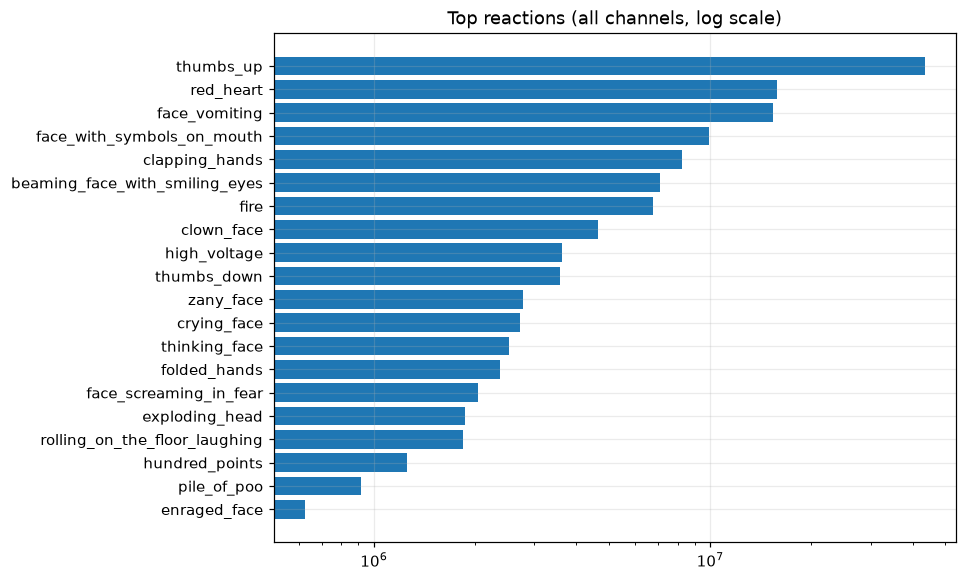

custom (premium) emoji: share of all reactions = 0.0


In [25]:
t = top.head(20).to_pandas().iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6)); ax.barh(t["name"], t["reactions"]); ax.set_xscale("log")
ax.set_title("Top reactions (all channels, log scale)"); savefig("02_top_reactions"); plt.show()
custom = rl.filter(pl.col("emoji").str.starts_with("custom_"))
print("custom (premium) emoji: share of all reactions =", round(custom["count"].sum() / rl["count"].sum(), 4))

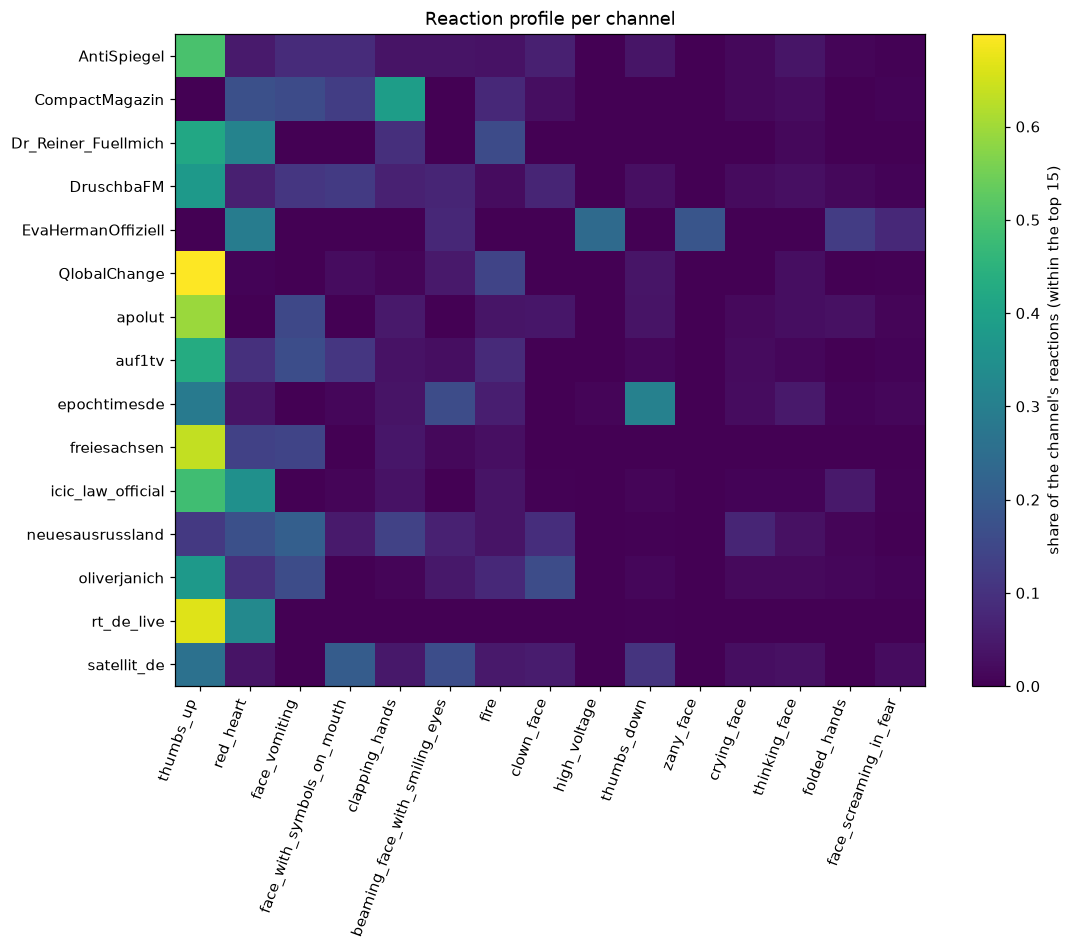

emoji,👍,❤,🤮,🤬,👏,😁,🔥,🤡,⚡,👎,🤪,😢,🤔,🙏,😱
channel,,,,,,,,,,,,,,,
AntiSpiegel,0.499,0.050,0.085,0.087,0.037,0.036,0.035,0.061,0.000,0.039,0.000,0.016,0.041,0.009,0.005
CompactMagazin,0.000,0.169,0.160,0.128,0.390,0.000,0.081,0.026,0.000,0.000,0.000,0.016,0.023,0.000,0.006
Dr_Reiner_Fuellmich,0.418,0.313,0.000,0.000,0.093,0.000,0.160,0.000,0.000,0.000,0.000,0.000,0.016,0.000,0.000
DruschbaFM,0.375,0.060,0.111,0.119,0.065,0.074,0.022,0.072,0.000,0.029,0.000,0.021,0.030,0.016,0.007
EvaHermanOffiziell,0.000,0.293,0.000,0.000,0.000,0.078,0.000,0.000,0.240,0.000,0.185,0.000,0.000,0.125,0.080
QlobalChange,0.699,0.006,0.000,0.023,0.010,0.047,0.143,0.000,0.000,0.041,0.000,0.001,0.025,0.002,0.003
apolut,0.594,0.000,0.152,0.000,0.048,0.000,0.039,0.043,0.002,0.037,0.000,0.017,0.026,0.032,0.009
auf1tv,0.430,0.098,0.166,0.111,0.035,0.025,0.082,0.000,0.000,0.013,0.000,0.019,0.013,0.000,0.008
epochtimesde,0.288,0.037,0.000,0.012,0.036,0.162,0.060,0.000,0.008,0.308,0.000,0.023,0.047,0.007,0.013


In [26]:
top_n = top.head(15)["emoji"].to_list()
ce = (rl.filter(pl.col("emoji").is_in(top_n)).group_by("channel", "emoji").agg(pl.col("count").sum()).to_pandas()
        .pivot(index="channel", columns="emoji", values="count").fillna(0).reindex(columns=top_n))
share = ce.div(ce.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 0.38 * len(share) + 2))
im = ax.imshow(share.to_numpy(), aspect="auto", cmap="viridis"); ax.grid(False)
ax.set_yticks(range(len(share)), share.index); ax.set_xticks(range(len(top_n)), [emoji_name(e) for e in top_n], rotation=70, ha="right")
plt.colorbar(im, label="share of the channel's reactions (within the top 15)"); ax.set_title("Reaction profile per channel")
savefig("02_reaction_profile"); plt.show()
share.round(3)

## 3. Positive / negative / ambivalent (heuristic)

Share of reaction counts by group, per channel and over time. Edit `REACTION_VALENCE` to change the grouping.

In [27]:
vmap = {e: valence_of(e) for e in rl["emoji"].unique().to_list()}
rv = rl.with_columns(pl.col("emoji").replace_strict(vmap, default="other").alias("valence"))
by_ch = rv.group_by("channel", "valence").agg(pl.col("count").sum()).to_pandas().pivot(index="channel", columns="valence", values="count").fillna(0)
by_ch = by_ch.div(by_ch.sum(axis=1), axis=0)
by_ch.round(3)

valence,ambivalent,negative,other,positive
channel,,,,
AntiSpiegel,0.045,0.293,0.000,0.662
CompactMagazin,0.027,0.301,0.000,0.672
Dr_Reiner_Fuellmich,0.016,0.000,0.000,0.984
DruschbaFM,0.040,0.345,0.000,0.615
EvaHermanOffiziell,0.074,0.044,0.194,0.689
QlobalChange,0.036,0.073,0.002,0.889
apolut,0.045,0.241,0.000,0.714
auf1tv,0.026,0.308,0.000,0.667
epochtimesde,0.060,0.330,0.024,0.586


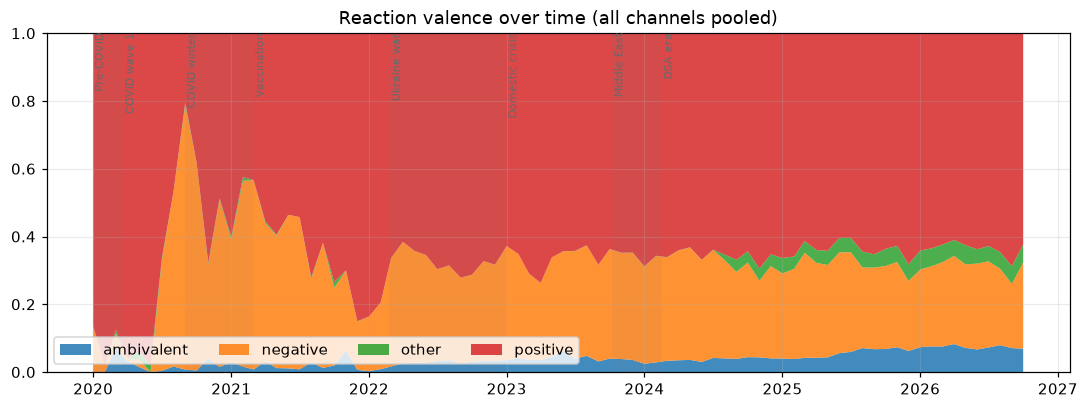

In [28]:
mon = (rv.with_columns(pl.col("day").dt.month_start().alias("month")).group_by("month", "valence").agg(pl.col("count").sum())
         .to_pandas().pivot(index="month", columns="valence", values="count").fillna(0).sort_index())
mon = mon.div(mon.sum(axis=1), axis=0)
PHASES = load_phases(os.environ.get("TG_PHASES")); EVENTS = load_events(os.environ.get("TG_EVENTS"))
fig, ax = plt.subplots(figsize=(12, 4))
ax.stackplot(pd.to_datetime(mon.index), mon.T.to_numpy(), labels=mon.columns, alpha=0.85)
ax.set_ylim(0, 1); ax.legend(loc="lower left", ncols=4); ax.set_title("Reaction valence over time (all channels pooled)")
shade_phases(ax, PHASES); savefig("02_valence_over_time"); plt.show()

## 4. Reaction rate: reactions per 1000 views

Normalising by views removes most of the "bigger channel = more reactions" effect.

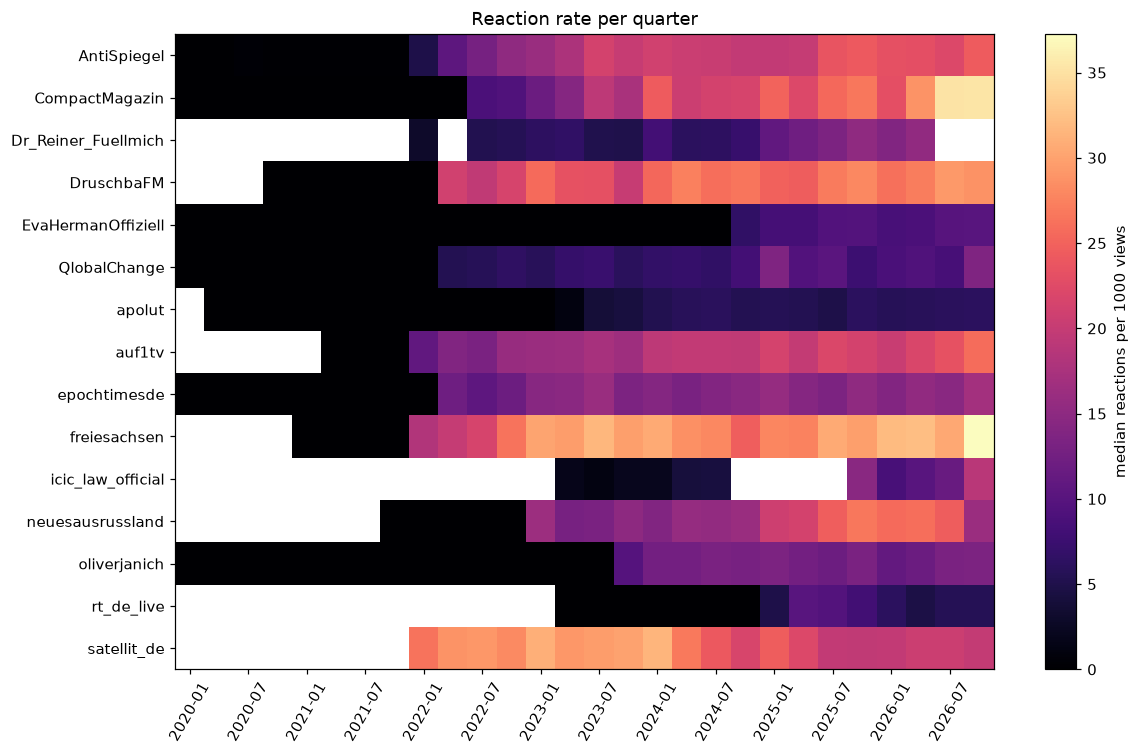

In [29]:
rate = (dr.filter(pl.col("views") > 0)
          .with_columns((pl.col("reactions_total") / pl.col("views") * 1000).alias("per_1000_views"),
                        pl.col("day").dt.truncate("3mo").alias("quarter")))
q = (rate.group_by("channel", "quarter").agg(pl.col("per_1000_views").median()).to_pandas()
         .pivot(index="channel", columns="quarter", values="per_1000_views"))
fig, ax = plt.subplots(figsize=(12, 0.38 * len(q) + 1.8))
im = ax.imshow(q.to_numpy().astype(float), aspect="auto", cmap="magma"); ax.grid(False)
ax.set_yticks(range(len(q)), q.index); ax.set_xticks(range(0, len(q.columns), 2), [str(c)[:7] for c in q.columns[::2]], rotation=60)
plt.colorbar(im, label="median reactions per 1000 views"); ax.set_title("Reaction rate per quarter")
savefig("02_reaction_rate"); plt.show()

In [30]:
from scipy.stats import spearmanr
rows = []
for ch, g in rate.group_by("channel"):
    if g.height > 30:
        rho, p = spearmanr(g["views"].to_numpy(), g["reactions_total"].to_numpy())
        rows.append({"channel": ch[0], "posts": g.height, "spearman_views_vs_reactions": round(float(rho), 3)})
pl.DataFrame(rows).sort("spearman_views_vs_reactions")

channel,posts,spearman_views_vs_reactions
str,i64,f64
"""oliverjanich""",149246,-0.586
"""apolut""",12661,-0.51
"""EvaHermanOffiziell""",223636,-0.258
"""QlobalChange""",18884,-0.145
"""CompactMagazin""",44135,-0.111
"""epochtimesde""",78167,-0.099
"""neuesausrussland""",30535,-0.052
"""satellit_de""",71143,0.321
"""auf1tv""",21598,0.355


## 5. How varied are the reactions? (entropy per post)

0 = everyone used the same emoji; higher = a mix. Computed only for posts with at least one reaction.

In [31]:
cols = reaction_columns(dr)
tot = pl.sum_horizontal([pl.col(c).fill_null(0) for c in cols])
terms = [pl.when(pl.col(c) > 0).then((pl.col(c) / tot) * (pl.col(c) / tot).log()).otherwise(0.0) for c in cols]
ent = (dr.with_columns(tot.alias("_t")).filter(pl.col("_t") > 0)
         .select("channel", "day", (-pl.sum_horizontal(terms)).alias("entropy")))
ent.group_by("channel").agg(pl.col("entropy").median().round(3).alias("median_entropy"), pl.len().alias("posts")).sort("median_entropy")

channel,median_entropy,posts
str,f64,u32
"""rt_de_live""",-0.0,16614
"""apolut""",0.562,8405
"""freiesachsen""",0.603,8731
"""QlobalChange""",0.63,8207
"""CompactMagazin""",0.665,27501
"""epochtimesde""",0.801,45525
"""Dr_Reiner_Fuellmich""",0.802,3021
"""AntiSpiegel""",0.824,13516
"""DruschbaFM""",0.836,67084


## 6. Reactions that go together

Spearman correlation between emoji shares across posts (top 12 emoji). Posts that draw many 😁 / 🤡 reactions - do they also draw 👎?

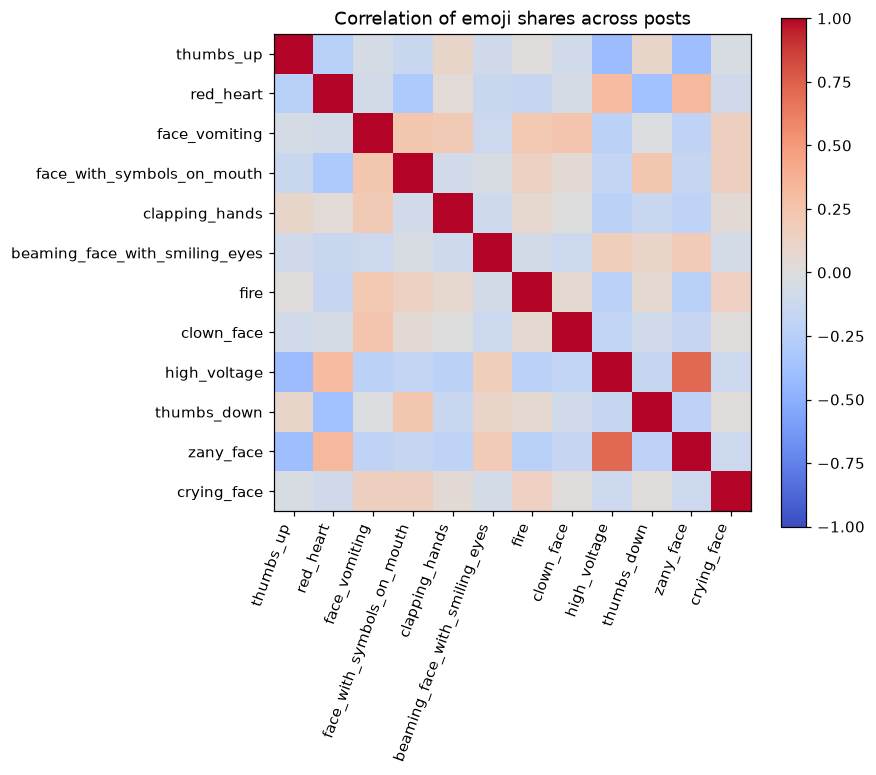

In [32]:
top12 = [f"reaction_{e}" for e in top.head(12)["emoji"].to_list() if f"reaction_{e}" in dr.columns]
s = dr.select(*[(pl.col(c).fill_null(0) / pl.col("reactions_total")).alias(c.replace("reaction_", "")) for c in top12], "reactions_total").filter(pl.col("reactions_total") > 4).drop("reactions_total")
corr = s.to_pandas().corr(method="spearman")
corr.columns = corr.index = [emoji_name(c) for c in corr.columns]
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr)), corr.columns, rotation=70, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
plt.colorbar(im); ax.set_title("Correlation of emoji shares across posts"); savefig("02_reaction_correlation"); plt.show()

## 7. Reading material: top posts

In [33]:
def show_top(frame, by, n=10):
    return (frame.sort(by, descending=True).head(n)
            .select("channel", "day", pl.col(by), "reactions_summary", "link", pl.col("text").str.slice(0, 140).str.replace_all("\n", " ").alias("text")))
show_top(dr, "reactions_total", 15)

channel,day,reactions_total,reactions_summary,link,text
str,date,i64,str,str,str
"""auf1tv""",2024-04-06,10193,"""❤ 8087 🥰 977 👍 707 👏 246 🎉 108 🤩 38 👎 11 🔥 6 😁 6 😱 6 😢 1""","""https://t.me/auf1tv/8157""","""Wir gratulieren AUF1-Frontfrau Elsa Mittmannsgruber und AUF1-Chefredak…"
"""auf1tv""",2023-02-10,8870,"""🤮 7354 🤬 563 👎 318 😁 258 👍 117 🤯 61 😱 60 🤔 58 🔥 41 🥰 24 ❤ 16""","""https://t.me/auf1tv/4771""","""Händchen halten, kuscheln, knuddeln. Wie findet ihr die neuen Umgangsf…"
"""auf1tv""",2023-01-29,7626,"""👍 5647 ❤ 1310 👏 464 😁 61 🥰 58 🤩 50 🔥 24 🤯 5 👎 4 🤔 3""","""https://t.me/auf1tv/4680""","""Djokovic: Ohne Spritze zurück an der Spitze 💉🏆 Letztes Jahr verweiger…"
"""auf1tv""",2022-04-24,7554,"""👎 3728 🤮 2807 🤬 479 😢 206 😱 95 👍 76 🤔 50 🔥 49 😁 31 🤯 29 ❤ 4""","""https://t.me/auf1tv/2194""","""Die französische Präsidentschaftswahl ist geschlagen. Der Young Global…"
"""auf1tv""",2024-06-02,7508,"""😢 5831 🤬 961 🤮 252 ❤ 131 👍 121 🔥 94 😱 57 🤔 26 😁 13 👎 11 👏 11""","""https://t.me/auf1tv/8704""","""+++EILT+++ Polizist verstorben! 🕯 Nun ist es traurige Gewissheit. Der…"
"""auf1tv""",2023-09-01,6888,"""🤮 5206 🤬 961 👎 248 😁 131 🤯 93 🔥 86 👍 82 ❤ 41 🎉 19 😱 15 🤩 6""","""https://t.me/auf1tv/6340""","""Der Gesundheitsminister des zweitgrößten Staates der EU will im Zuge d…"
"""neuesausrussland""",2022-12-12,6785,"""❤ 5621 👏 1002 🤮 48 🤡 41 🔥 32 🎉 20 🤔 11 😁 7 🤯 3""","""https://t.me/neuesausrussland/11973""","""❗️Ich nehme mir nach einem Jahr Kanalarbeit ein wenig Urlaub über die …"
"""auf1tv""",2024-03-14,6757,"""❤ 4421 👍 1521 👏 476 🎉 128 🥰 84 🔥 42 🤩 40 😁 16 🤯 13 🤮 10 😱 6""","""https://t.me/auf1tv/7965""","""Wir haben es geschafft! Gemeinsam konnte der Vernichtungsschlag des Sy…"
"""auf1tv""",2022-01-20,6714,"""🤮 4806 😢 732 💩 470 👎 416 😱 128 🔥 62 👍 57 🎉 26 😁 17""","""https://t.me/auf1tv/1269""","""Gute Nacht Österreich."""


In [34]:
EMOJI = "🤡"   # change to look at other reactions
col = f"reaction_{EMOJI}"
show_top(dr.filter(pl.col(col).is_not_null()), col, 10) if col in dr.columns else print("no column", col)

channel,day,reaction_🤡,reactions_summary,link,text
str,date,i64,str,str,str
"""neuesausrussland""",2023-06-29,3201,"""🤡 3201 🤮 965 😁 464 🤯 84 👏 25 🔥 18 🤔 16 🎉 16 😢 11 ❤ 9""","""https://t.me/neuesausrussland/14931""","""🤓 Greta Thunberg findet, dass die Bevölkerung der Ukraine zu viel Kohl…"
"""neuesausrussland""",2023-03-19,3126,"""🤡 3126 🤮 1140 😁 288 👏 57 ❤ 41 🤯 30 🔥 26 🤔 12 🎉 7 😢 3""","""https://t.me/neuesausrussland/13460""","""🇩🇪❗️„Ich gehe davon aus, dass der IStGH schnell auf Interpol und die V…"
"""neuesausrussland""",2023-06-11,2754,"""🤡 2754 🤮 1226 😁 119 🤯 63 👏 41 ❤ 33 🤔 22 😢 17 🔥 12 🎉 6""","""https://t.me/neuesausrussland/14494""","""In Deutschland sind Menschen in einen Fluss geklettert und beschuldige…"
"""neuesausrussland""",2023-01-07,2609,"""🤡 2609 😁 584 🤮 457 🤯 62 🤔 43 👏 37 🔥 14 🎉 12 ❤ 9 😢 3""","""https://t.me/neuesausrussland/12184""","""⚡️""Die Ukraine wird bald ganz Russland plattbügeln. Inklusive des Ural…"
"""neuesausrussland""",2023-06-04,2580,"""🤡 2580 🤮 441 😁 295 🤯 82 ❤ 42 🤔 27 🔥 16 🎉 16 👏 13""","""https://t.me/neuesausrussland/14330""","""🤣🤡 Größenwahnsinnig: ""Nach dem Zusammenbruch Russlands und der Eroberu…"
"""neuesausrussland""",2023-10-18,2370,"""🤡 2370 😁 348 🤮 314 🤔 41 ❤ 23 🤯 18 👏 16 🔥 13 🎉 10 😢 2""","""https://t.me/neuesausrussland/16567""","""⚡️🤡 ""Der Staat Israel wurde für die Sicherheit der Juden auf der ganze…"
"""neuesausrussland""",2023-01-27,2352,"""🤡 2352 🤮 515 😁 157 🤯 43 🤔 36 👏 14 ❤ 12 😢 11 🔥 5 🎉 5""","""https://t.me/neuesausrussland/12518""","""Bitte nicht beachten... Das Außenministerium Deutschlands verkündete,…"
"""neuesausrussland""",2022-11-22,2208,"""🤡 2208 🤣 1121 🤮 205 👏 140 😁 94 🤔 44 🤯 28 🎉 26 😢 22 ❤ 18 🔥 16""","""https://t.me/neuesausrussland/11689""","""🇩🇪 Bundeswehr-Generalinspekteur Eberhard Zorn: „Russischer Angriff a…"
"""neuesausrussland""",2023-12-07,2178,"""🤡 2178 😁 493 🤮 142 👏 35 🤔 18 ❤ 17 🤯 11 🔥 8 😢 2""","""https://t.me/neuesausrussland/17270""","""❗️Klitschko warf Selenskij vor, „die Ukraine in einen autoritären Staa…"


## 8. Emoji in the posts' own text

In [35]:
tx = (df.filter(pl.col("has_text")).with_columns(emojis_in_text().alias("emojis"))
        .with_columns(pl.col("emojis").list.len().alias("n_emoji")))
per_channel = tx.group_by("channel").agg(
    (pl.col("n_emoji") > 0).mean().round(3).alias("share_posts_with_emoji"),
    (pl.col("n_emoji").sum() / pl.col("n_words").sum() * 100).round(2).alias("emoji_per_100_words"),
    pl.len().alias("text_posts")).sort("share_posts_with_emoji", descending=True)
per_channel

channel,share_posts_with_emoji,emoji_per_100_words,text_posts
str,f64,f64,u32
"""Dr_Reiner_Fuellmich""",0.974,3.61,3021
"""auf1tv""",0.925,2.76,20332
"""NachDenkSeiten_DE""",0.876,5.7,4833
"""CompactMagazin""",0.862,5.22,42264
"""DruschbaFM""",0.852,4.05,65075
"""neuesausrussland""",0.788,3.06,19037
"""rt_de_live""",0.731,2.91,29211
"""satellit_de""",0.648,1.7,51461
"""kenjebsen""",0.563,0.96,20700


In [36]:
top_text = (tx.select("emojis").explode("emojis").drop_nulls().group_by("emojis").len().sort("len", descending=True).head(25)
              .with_columns(pl.col("emojis").map_elements(emoji_name, return_dtype=pl.Utf8).alias("name")))
top_text

emojis,len,name
str,u32,str
"""👉""",180146,"""backhand_index_pointing_right"""
"""‼""",99581,"""double_exclamation_mark"""
"""❗""",92009,"""red_exclamation_mark"""
"""💥""",44849,"""collision"""
"""➡""",41886,"""right_arrow"""
"""▪""",30845,"""black_small_square"""
"""🔥""",27919,"""fire"""
"""📺""",27806,"""television"""
"""📱""",22830,"""mobile_phone"""


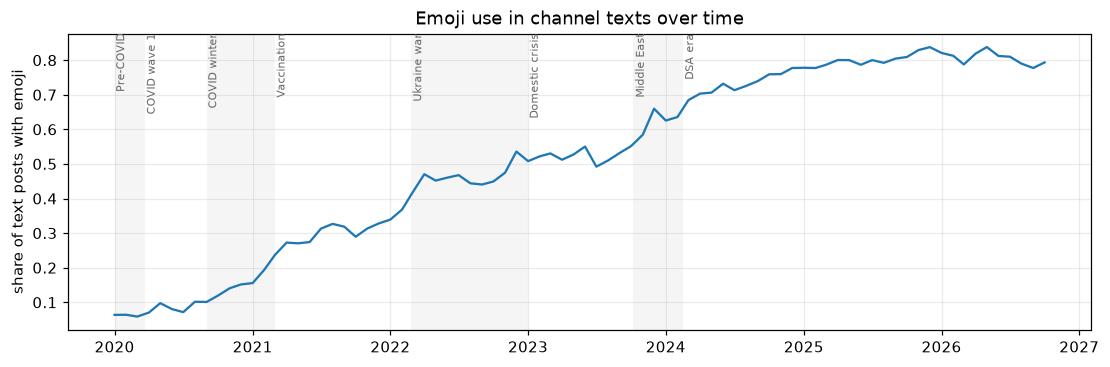

In [37]:
mt = (tx.group_by("month").agg((pl.col("n_emoji") > 0).mean().alias("share")).sort("month").to_pandas())
fig, ax = plt.subplots(figsize=(12, 3.5)); ax.plot(pd.to_datetime(mt["month"]), mt["share"])
ax.set_ylabel("share of text posts with emoji"); shade_phases(ax, PHASES); ax.set_title("Emoji use in channel texts over time")
savefig("02_text_emoji_over_time"); plt.show()

In [38]:
by_phase = (assign_phase(tx.select("day", "emojis"), PHASES).filter(pl.col("phase").is_not_null())
              .explode("emojis").drop_nulls().group_by("phase", "emojis").len()
              .sort("phase", "len", descending=[False, True]).group_by("phase", maintain_order=True).head(5)
              .with_columns(pl.col("emojis").map_elements(emoji_name, return_dtype=pl.Utf8).alias("name")))
by_phase

phase,emojis,len,name
enum,str,u32,str
"""Pre-COVID""","""🗞""",151,"""rolled-up_newspaper"""
"""Pre-COVID""","""▶""",97,"""play_button"""
"""Pre-COVID""","""📁""",73,"""file_folder"""
"""Pre-COVID""","""😎""",52,"""smiling_face_with_sunglasses"""
"""Pre-COVID""","""🌴""",38,"""palm_tree"""
"""COVID wave 1""","""‼""",4645,"""double_exclamation_mark"""
"""COVID wave 1""","""▶""",1252,"""play_button"""
"""COVID wave 1""","""🙏""",784,"""folded_hands"""
"""COVID wave 1""","""📁""",511,"""file_folder"""


## 9. Most approved, most disapproved and most controversial posts

Every reaction emoji is coded in `config/emoji_emotions.csv` with a **stance**: `approve` (👍 ❤ 🔥 👏 ...),
`disapprove` (👎 🤬 🤮 🤡 ...) or `neutral`. For every post with at least `MIN_REACT` reactions:

* **approved** = ranked by the *Wilson lower bound* of the approving share (so 5 of 5 reactions does not beat 900 of 1000),
* **disapproved** = same for disapproving reactions,
* **controversial** = `2 x min(approve, disapprove)` - big *and* balanced (the Reddit-style controversy score).

**Read with care:** a 🤡 or 👎 may mock the *target* of the post rather than disapprove of the channel (e.g. a post about
a politician). Reactions measure how the audience feels about the message, not whether it is true. Edit the `stance`
column in the csv to change the coding, and always read the posts (links below).

In [39]:
MIN_REACT = 20                       # ignore posts with fewer reactions
CB = load_emoji_emotions()           # config/emoji_emotions.csv
SC = assign_phase(post_reaction_scores(dr, CB, min_reactions=MIN_REACT), PHASES)
print(f"{SC.height:,} posts with >= {MIN_REACT} reactions")
uncl = (reaction_long(dr, index=("channel",)).with_columns(pl.col("emoji").str.replace_all("️", "", literal=True))
        .join(CB.select("emoji", "stance"), on="emoji", how="left").with_columns(pl.col("stance").is_null().alias("unclassified"))
        .group_by("unclassified").agg(pl.col("count").sum()))
print("reactions covered by the codebook:", uncl.to_dicts())

365,548 posts with >= 20 reactions
reactions covered by the codebook: [{'unclassified': False, 'count': 136245531}, {'unclassified': True, 'count': 3886820}]


In [41]:
display(top_posts(SC, "approved", 15))

phase,channel,id,day,n_reactions,approve,disapprove,approve_wilson,snippet,link
enum,str,i64,date,i64,i64,i64,f64,str,str
"""Vaccination""","""auf1tv""",1408,2022-02-06,3681,3680,1,0.998463,"""Film „ZEUGEN DER WAHRHEIT“ erzielt enorme Reichweite! Mehr als 20.000 …","""https://t.me/auf1tv/1408"""
"""Vaccination""","""auf1tv""",1278,2022-01-21,3407,3406,1,0.998339,"""Erstmals meldet sich in Kärnten ein renommierter Mediziner mit Argumen…","""https://t.me/auf1tv/1278"""
"""Vaccination""","""auf1tv""",1351,2022-01-29,4511,4508,3,0.998046,"""Trotz Eis, Wind, Regen: Die Ringstraße in Wien ist mit Abertausenden v…","""https://t.me/auf1tv/1351"""
"""DSA era""","""auf1tv""",20630,2026-07-25,1870,1870,0,0.99795,"""💣💥Merz muss weg! – Wir wollen Frieden! Gegen die Kriegspolitik von Kan…","""https://t.me/auf1tv/20630"""
"""Vaccination""","""auf1tv""",1427,2022-02-09,4169,4166,3,0.997886,"""Die Wahrheit dringt ans Licht und die Mächtigen befinden sich immer me…","""https://t.me/auf1tv/1427"""
"""DSA era""","""auf1tv""",9114,2024-07-03,2453,2452,0,0.997694,"""👨🏼‍⚕️Corona-Helden: Wir vergessen Euch nicht! Getreu ihrem geleisteten…","""https://t.me/auf1tv/9114"""
"""DSA era""","""auf1tv""",8837,2024-06-12,1656,1656,0,0.997686,"""Stehen wir zusammen! Klären wir auf! Retten wir Leben! Bei Corona habe…","""https://t.me/auf1tv/8837"""
"""DSA era""","""auf1tv""",10115,2024-09-29,2381,2380,0,0.997625,"""Kickl-Vize Susanne Fürst im AUF1-Wahlstudio: „Es hat sich alles geände…","""https://t.me/auf1tv/10115"""
"""DSA era""","""auf1tv""",9843,2024-09-12,1579,1579,0,0.997573,"""‼️Die NACHRICHTEN AUF1 sind da‼️ ▶️ https://auf1.tv/nachrichten-auf1/n…","""https://t.me/auf1tv/9843"""


In [42]:
display(top_posts(SC, "disapproved", 15))

phase,channel,id,day,n_reactions,approve,disapprove,disapprove_wilson,snippet,link
enum,str,i64,date,i64,i64,i64,f64,str,str
"""DSA era""","""CompactMagazin""",35519,2025-01-24,1033,5,1028,0.988719,"""🌹🕯️ Aschaffenburg: Der Blockadering der Antifa rund um die Gedächtniss…","""https://t.me/CompactMagazin/35519"""
"""Ukraine war""","""DruschbaFM""",8650,2022-11-21,330,0,330,0.988493,"""⚡️ Parlamentarische Versammlung der NATO erkennt Russland als „terrori…","""https://t.me/DruschbaFM/8650"""
"""Ukraine war""","""DruschbaFM""",7337,2022-10-24,317,0,317,0.988026,"""https://www.heise.de/tp/features/Friedenspreis-fuer-Russen-Hass-731732…","""https://t.me/DruschbaFM/7337"""
"""Ukraine war""","""DruschbaFM""",7539,2022-10-28,313,0,313,0.987875,"""🇩🇪🇷🇺Bundespräsident Steinmeier: Deutschland und Russland stehen gegene…","""https://t.me/DruschbaFM/7539"""
"""DSA era""","""oliverjanich""",155262,2025-05-02,458,0,457,0.987737,"""Nach der Einstufung der AfD als gesichert rechtsextremistisch hat Bund…","""https://t.me/oliverjanich/155262"""
"""DSA era""","""CompactMagazin""",34745,2024-12-12,454,1,453,0.98763,"""Scholzens billiger Trick 🍞🍎🍗 Zitat des Tages: „Vielleicht war der Kanz…","""https://t.me/CompactMagazin/34745"""
"""Domestic crisis""","""CompactMagazin""",24622,2023-03-29,303,0,303,0.98748,"""Zitat des Tages: „Ja, mit den Grünen kann man Armut überwinden“ (Ricar…","""https://t.me/CompactMagazin/24622"""
"""Ukraine war""","""DruschbaFM""",7316,2022-10-23,294,0,294,0.987102,"""🇺🇦 💀 SELENSKIJ FORDERT VON WESTEN RAKETENSCHLÄGE AUF DEN KREML Der ukr…","""https://t.me/DruschbaFM/7316"""
"""DSA era""","""oliverjanich""",146779,2024-10-25,670,0,667,0.986919,"""🔥Habeck fordert noch härtere Zensur als der Digital Service Act bereit…","""https://t.me/oliverjanich/146779"""


In [43]:
display(top_posts(SC, "controversial", 15))

phase,channel,id,day,n_reactions,approve,disapprove,controversy,snippet,link
enum,str,i64,date,i64,i64,i64,i64,str,str
"""DSA era""","""auf1tv""",10069,2024-09-28,3792,1834,1894,3668,"""""","""https://t.me/auf1tv/10069"""
"""DSA era""","""auf1tv""",9013,2024-06-26,3653,1848,1711,3422,"""‼️ Wenn das Kommentieren von Verbrechen folgenschwerer ist als das Ver…","""https://t.me/auf1tv/9013"""
"""DSA era""","""auf1tv""",11102,2024-11-30,3465,1707,1692,3384,"""🚨 🇦🇹 Massive Polizeiprovokation bei patriotischer Demonstration in Wie…","""https://t.me/auf1tv/11102"""
"""DSA era""","""auf1tv""",8894,2024-06-17,3989,2236,1633,3266,"""🧨 Werden 100.000 Linksextremisten den AfD-Parteitag in Essen stürmen? …","""https://t.me/auf1tv/8894"""
"""Ukraine war""","""auf1tv""",4463,2022-12-21,3371,1644,1631,3262,"""Rauswurf knapp vor Weihnachten: Fußballverein feuert unseren AUF1-Mita…","""https://t.me/auf1tv/4463"""
"""Domestic crisis""","""auf1tv""",6614,2023-10-04,3935,2266,1590,3180,"""Skandalurteil: Kellner wegen Beleidigung zu 11.000 € Geldstrafe verurt…","""https://t.me/auf1tv/6614"""
"""Middle East""","""auf1tv""",6896,2023-11-06,4150,2424,1564,3128,"""Keine AUF1-Nachrichten im Fernsehen: „Das riecht gewaltig nach Sabotag…","""https://t.me/auf1tv/6896"""
"""DSA era""","""auf1tv""",12405,2025-02-26,3830,2082,1549,3098,"""+++EILT! ⛓ Calin Georgescu in Rumänien verhaftet Heute fanden in ganz …","""https://t.me/auf1tv/12405"""
"""DSA era""","""auf1tv""",12195,2025-02-16,3491,1535,1810,3070,"""🔪 Messer-Amok in Villach: Hier grinst der Kindermörder in die Kamera! …","""https://t.me/auf1tv/12195"""


Per channel (top 3 each):

In [44]:
top_posts(SC, "approved", 3, by="channel").sort("channel")

phase,channel,id,day,n_reactions,approve,disapprove,approve_wilson,snippet,link
enum,str,i64,date,i64,i64,i64,f64,str,str
"""DSA era""","""AntiSpiegel""",10546,2024-09-10,1652,1649,3,0.994674,"""""","""https://t.me/AntiSpiegel/10546"""
"""DSA era""","""AntiSpiegel""",11738,2025-02-26,1315,1313,2,0.994471,"""📢 Georgescu bekräftigt seine Entschlossenheit, für das Amt des rumänis…","""https://t.me/AntiSpiegel/11738"""
"""Domestic crisis""","""AntiSpiegel""",6930,2023-08-15,686,686,0,0.994431,"""📝 Reportage: Wie Mariupol heute aussieht ➥ Hier den Artikel lesen Letz…","""https://t.me/AntiSpiegel/6930"""
"""DSA era""","""CompactMagazin""",41802,2025-12-14,697,697,0,0.994519,"""Erzgebirge: Mutige Bürger stoppen Antifa 🟥 Das erlebt die Antifa nicht…","""https://t.me/CompactMagazin/41802"""
"""DSA era""","""CompactMagazin""",44453,2026-05-11,624,624,0,0.993881,"""Der erste Bürgermeister der AfD in Brandenburg! 💙 🇩🇪 Zeit für die Wend…","""https://t.me/CompactMagazin/44453"""
"""Middle East""","""CompactMagazin""",28349,2023-12-10,617,617,0,0.993812,"""Höcke verspricht: Remigration und Verabschiedungs-Kultur 🧑🏽‍🦱👳🏾‍♀️ Ref…","""https://t.me/CompactMagazin/28349"""
"""Vaccination""","""Dr_Reiner_Fuellmich""",3,2022-02-12,65,65,0,0.944197,"""Recently, the Biden administration has censored me on every social net…","""https://t.me/Dr_Reiner_Fuellmich/3"""
"""Ukraine war""","""Dr_Reiner_Fuellmich""",277,2022-11-09,38,38,0,0.908187,"""☀️ ICIC - International Crimes Investigative Committee ☀️ The German-A…","""https://t.me/Dr_Reiner_Fuellmich/277"""
"""Domestic crisis""","""Dr_Reiner_Fuellmich""",1059,2023-04-26,36,36,0,0.903578,"""I think we are a lot closer to the bottom frame than people realize. K…","""https://t.me/Dr_Reiner_Fuellmich/1059"""


In [45]:
top_posts(SC, "disapproved", 3, by="channel").sort("channel")

phase,channel,id,day,n_reactions,approve,disapprove,disapprove_wilson,snippet,link
enum,str,i64,date,i64,i64,i64,f64,str,str
"""DSA era""","""AntiSpiegel""",8859,2024-03-07,1952,31,1914,0.973394,"""📢 Baerbock: Kiew soll mehr Langstreckenwaffen bekommen. Diese Ticker-M…","""https://t.me/AntiSpiegel/8859"""
"""Middle East""","""AntiSpiegel""",8488,2024-01-30,971,17,951,0.968399,"""📢 Borrell bezeichnet Ideen über einen möglichen Waffenstillstand in de…","""https://t.me/AntiSpiegel/8488"""
"""DSA era""","""AntiSpiegel""",8833,2024-03-05,1599,33,1562,0.968269,"""📢 Die EU will Erlöse aus russischen Vermögenswerten zur Unterstützung …","""https://t.me/AntiSpiegel/8833"""
"""DSA era""","""CompactMagazin""",35519,2025-01-24,1033,5,1028,0.988719,"""🌹🕯️ Aschaffenburg: Der Blockadering der Antifa rund um die Gedächtniss…","""https://t.me/CompactMagazin/35519"""
"""DSA era""","""CompactMagazin""",34745,2024-12-12,454,1,453,0.98763,"""Scholzens billiger Trick 🍞🍎🍗 Zitat des Tages: „Vielleicht war der Kanz…","""https://t.me/CompactMagazin/34745"""
"""Domestic crisis""","""CompactMagazin""",24622,2023-03-29,303,0,303,0.98748,"""Zitat des Tages: „Ja, mit den Grünen kann man Armut überwinden“ (Ricar…","""https://t.me/CompactMagazin/24622"""
"""Ukraine war""","""Dr_Reiner_Fuellmich""",94,2022-09-27,22,22,0,1.1815e-17,"""Interview portrait with Dr. Reiner Fuellmich ""My motivation is to port…","""https://t.me/Dr_Reiner_Fuellmich/94"""
"""Ukraine war""","""Dr_Reiner_Fuellmich""",287,2022-11-11,22,22,0,1.1815e-17,"""India: Court Date Set for Bill Gates to Answer to Victims’ Family for …","""https://t.me/Dr_Reiner_Fuellmich/287"""
"""Domestic crisis""","""Dr_Reiner_Fuellmich""",1007,2023-04-03,22,22,0,1.1815e-17,"""💥""We will make the mainstream media tell the truth on themselves about…","""https://t.me/Dr_Reiner_Fuellmich/1007"""


Per period (top 3 each) - which messages were loved / hated in COVID wave 1, Vaccination, Ukraine war ...?

In [51]:
SCp = SC.filter(pl.col("phase").is_not_null())
display(top_posts(SCp, "approved", 3, by="phase"))
display(top_posts(SCp, "disapproved", 3, by="phase"))

phase,channel,id,day,n_reactions,approve,disapprove,approve_wilson,snippet,link
enum,str,i64,date,i64,i64,i64,f64,str,str
"""Vaccination""","""auf1tv""",1408,2022-02-06,3681,3680,1,0.998463,"""Film „ZEUGEN DER WAHRHEIT“ erzielt enorme Reichweite! Mehr als 20.000 …","""https://t.me/auf1tv/1408"""
"""Vaccination""","""auf1tv""",1278,2022-01-21,3407,3406,1,0.998339,"""Erstmals meldet sich in Kärnten ein renommierter Mediziner mit Argumen…","""https://t.me/auf1tv/1278"""
"""Vaccination""","""auf1tv""",1351,2022-01-29,4511,4508,3,0.998046,"""Trotz Eis, Wind, Regen: Die Ringstraße in Wien ist mit Abertausenden v…","""https://t.me/auf1tv/1351"""
"""DSA era""","""auf1tv""",20630,2026-07-25,1870,1870,0,0.99795,"""💣💥Merz muss weg! – Wir wollen Frieden! Gegen die Kriegspolitik von Kan…","""https://t.me/auf1tv/20630"""
"""DSA era""","""auf1tv""",9114,2024-07-03,2453,2452,0,0.997694,"""👨🏼‍⚕️Corona-Helden: Wir vergessen Euch nicht! Getreu ihrem geleisteten…","""https://t.me/auf1tv/9114"""
"""DSA era""","""auf1tv""",8837,2024-06-12,1656,1656,0,0.997686,"""Stehen wir zusammen! Klären wir auf! Retten wir Leben! Bei Corona habe…","""https://t.me/auf1tv/8837"""
"""Ukraine war""","""auf1tv""",4093,2022-11-17,2771,2769,2,0.997372,"""Als Schweizer Rechtsanwalt ist Philip Kruse Verfasser einer 318-Seiten…","""https://t.me/auf1tv/4093"""
"""Ukraine war""","""auf1tv""",1605,2022-02-28,4984,4974,1,0.99631,"""Ein Vorbild für den Corona-Widerstand: Trotz Mobbing und Ausschluss vo…","""https://t.me/auf1tv/1605"""
"""Ukraine war""","""auf1tv""",2838,2022-06-28,2345,2342,2,0.996245,"""Eine Kleinmaschine staunte nicht schlecht, als sie neulich in Westdeut…","""https://t.me/auf1tv/2838"""


phase,channel,id,day,n_reactions,approve,disapprove,disapprove_wilson,snippet,link
enum,str,i64,date,i64,i64,i64,f64,str,str
"""DSA era""","""CompactMagazin""",35519,2025-01-24,1033,5,1028,0.988719,"""🌹🕯️ Aschaffenburg: Der Blockadering der Antifa rund um die Gedächtniss…","""https://t.me/CompactMagazin/35519"""
"""DSA era""","""oliverjanich""",155262,2025-05-02,458,0,457,0.987737,"""Nach der Einstufung der AfD als gesichert rechtsextremistisch hat Bund…","""https://t.me/oliverjanich/155262"""
"""DSA era""","""CompactMagazin""",34745,2024-12-12,454,1,453,0.98763,"""Scholzens billiger Trick 🍞🍎🍗 Zitat des Tages: „Vielleicht war der Kanz…","""https://t.me/CompactMagazin/34745"""
"""Ukraine war""","""DruschbaFM""",8650,2022-11-21,330,0,330,0.988493,"""⚡️ Parlamentarische Versammlung der NATO erkennt Russland als „terrori…","""https://t.me/DruschbaFM/8650"""
"""Ukraine war""","""DruschbaFM""",7337,2022-10-24,317,0,317,0.988026,"""https://www.heise.de/tp/features/Friedenspreis-fuer-Russen-Hass-731732…","""https://t.me/DruschbaFM/7337"""
"""Ukraine war""","""DruschbaFM""",7539,2022-10-28,313,0,313,0.987875,"""🇩🇪🇷🇺Bundespräsident Steinmeier: Deutschland und Russland stehen gegene…","""https://t.me/DruschbaFM/7539"""
"""Domestic crisis""","""CompactMagazin""",24622,2023-03-29,303,0,303,0.98748,"""Zitat des Tages: „Ja, mit den Grünen kann man Armut überwinden“ (Ricar…","""https://t.me/CompactMagazin/24622"""
"""Domestic crisis""","""CompactMagazin""",23493,2023-01-16,350,0,349,0.983995,"""Anne Will: Roter Teppich für Greta und Luisa 🔥 💥 🟩 Der TV-Talk „Anne W…","""https://t.me/CompactMagazin/23493"""
"""Domestic crisis""","""CompactMagazin""",23569,2023-01-22,201,0,201,0.981246,"""Klimakleber sind erwünschte Staatsfeinde 💥 🔥 Zitat des Tages: „Erwünsc…","""https://t.me/CompactMagazin/23569"""


In [52]:
share = (SC.group_by("channel").agg(pl.col("approve").sum().alias("approve"), pl.col("disapprove").sum().alias("disapprove"),
                                    pl.col("n_reactions").sum().alias("reactions"))
           .with_columns((pl.col("approve") / pl.col("reactions")).round(3).alias("approve_share"),
                         (pl.col("disapprove") / pl.col("reactions")).round(3).alias("disapprove_share"))
           .sort("disapprove_share", descending=True))
share.write_csv(FIG / "02_approval_by_channel.csv"); share

channel,approve,disapprove,reactions,approve_share,disapprove_share
str,i64,i64,i64,f64,f64
"""neuesausrussland""",6991314,5624342,16175454,0.432,0.348
"""oliverjanich""",4997202,3155691,9424064,0.53,0.335
"""satellit_de""",4674643,4016606,12433367,0.376,0.323
"""DruschbaFM""",4862638,2969750,9334165,0.521,0.318
"""epochtimesde""",1382608,1026505,3337351,0.414,0.308
"""auf1tv""",23194415,10424511,36113965,0.642,0.289
"""CompactMagazin""",4732743,2189160,7652665,0.618,0.286
"""AntiSpiegel""",6415896,3269805,11739940,0.547,0.279
"""apolut""",681985,225380,1001682,0.681,0.225


In [53]:
for kind in ("approved", "disapproved", "controversial"):
    top_posts(SC, kind, 50).write_csv(FIG / f"02_top_{kind}.csv")
top_posts(SCp, "approved", 5, by="phase").write_csv(FIG / "02_top_approved_by_period.csv")
top_posts(SCp, "disapproved", 5, by="phase").write_csv(FIG / "02_top_disapproved_by_period.csv")

## 10. Emotions behind the emoji

The codebook assigns every emoji to an **emotion** and a broader **family**. The scheme combines established frameworks:

| Family | Emotions (examples) | Theory |
|---|---|---|
| `fear` | fear, anxiety (😱 😨 😰) | Ekman basic emotion; Plutchik "fear" |
| `hostility` ("hatred") | anger, disgust, contempt (🤬 😡 🤮 🤡 🖕) | Sternberg's duplex theory of hate (negation of intimacy = disgust, passion = anger/fear, commitment = contempt); Matsumoto & Ekman: contempt as basic emotion |
| `peace_hope` | peace, hope (🕊 🙏 😇) | Russell circumplex: pleasant + *low arousal* = calm; Plutchik dyad anticipation + trust = hope |
| `joy_affection` | joy, love, trust (❤ 🔥 🎉 👏) | Ekman happiness; Plutchik dyad joy + trust = love |
| `sadness` | sadness, loss (😢 😭 💔) | Ekman / Plutchik |
| `epistemic` | surprise, doubt, anticipation (🤯 🤔 👀) | Silvia (2010) epistemic emotions; Plutchik surprise / anticipation |
| `other` | boredom (🥱 😴) | Russell low-arousal unpleasant |

Plain 👍 / 👎 are social signals (`none`), not emotions, and are excluded from the shares below. The mapping is a
*researcher-coded dictionary* in `config/emoji_emotions.csv`, not a validated measure: emoji are ambiguous (😁 🤡 ironic),
and reacting with 😱 to a post can mean "this is frightening" or "this is outrageous". For a publication, validate it
on a hand-coded sample (Cohen's kappa) and check robustness with the Emoji Sentiment Ranking (Kralj Novak et al. 2015).

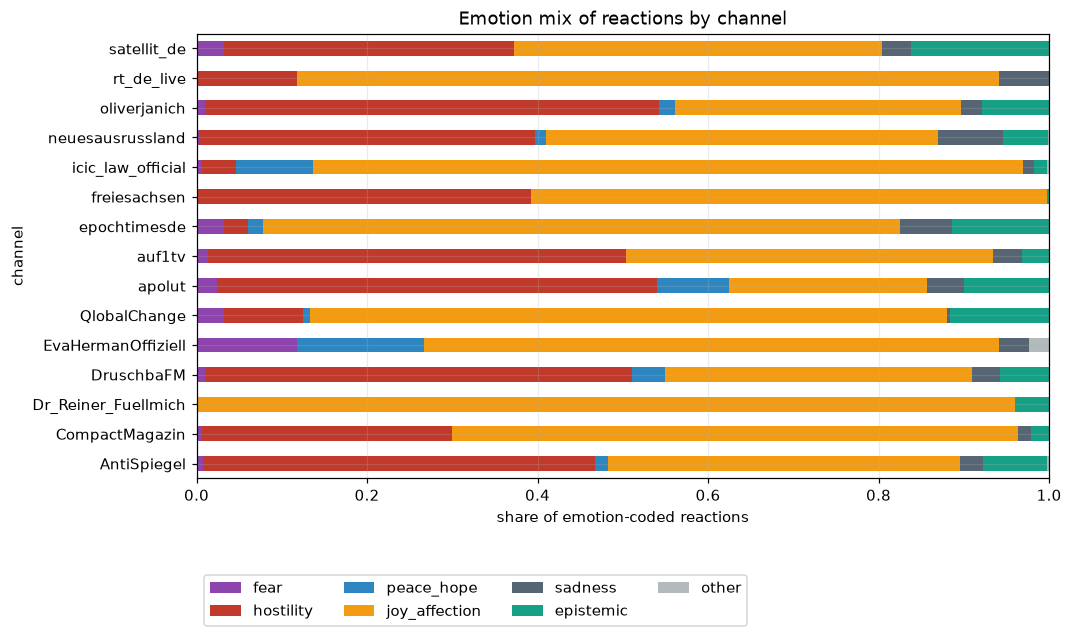

channel,sadness,joy_affection,other,hostility,epistemic,peace_hope,fear
str,f64,f64,f64,f64,f64,f64,f64
"""AntiSpiegel""",0.026592,0.413102,0.002113,0.459859,0.075699,0.015221,0.007415
"""CompactMagazin""",0.015241,0.663019,0.0,0.29411,0.021712,0.0,0.005918
"""Dr_Reiner_Fuellmich""",0.0,0.95951,0.0,0.0,0.04049,0.0,0.0
"""DruschbaFM""",0.033491,0.359508,0.000104,0.500723,0.05714,0.038661,0.010373
"""EvaHermanOffiziell""",0.034628,0.674142,0.024117,0.0,0.0,0.149344,0.11777
"""QlobalChange""",0.003557,0.746846,0.0,0.092473,0.116423,0.007969,0.032732
"""apolut""",0.04428,0.231899,0.0,0.517034,0.099469,0.083701,0.023618
"""auf1tv""",0.033743,0.430391,0.0,0.490012,0.031939,0.0,0.013916
"""epochtimesde""",0.060098,0.748191,0.0,0.028688,0.114314,0.017113,0.031594


In [54]:
FAM_ORDER = ["fear", "hostility", "peace_hope", "joy_affection", "sadness", "epistemic", "other"]
FAM_COL = {"fear": "#8e44ad", "hostility": "#c0392b", "peace_hope": "#2e86c1", "joy_affection": "#f39c12",
           "sadness": "#566573", "epistemic": "#16a085", "other": "#b2babb"}
def fams(frame):
    have = [f for f in FAM_ORDER if f in frame.columns]
    return have
prof = emotion_profile(SC, by=("channel",)).sort("channel")
prof.write_csv(FIG / "02_emotion_profile_by_channel.csv")
pp = prof.to_pandas().set_index("channel")[fams(prof)]
ax = pp.plot(kind="barh", stacked=True, figsize=(10, max(3, 0.35 * len(pp))), color=[FAM_COL[c] for c in pp.columns])
ax.set_xlabel("share of emotion-coded reactions"); ax.set_title("Emotion mix of reactions by channel"); ax.legend(ncol=4, bbox_to_anchor=(0, -0.2), loc="upper left")
savefig("02_emotion_by_channel"); plt.show()
prof

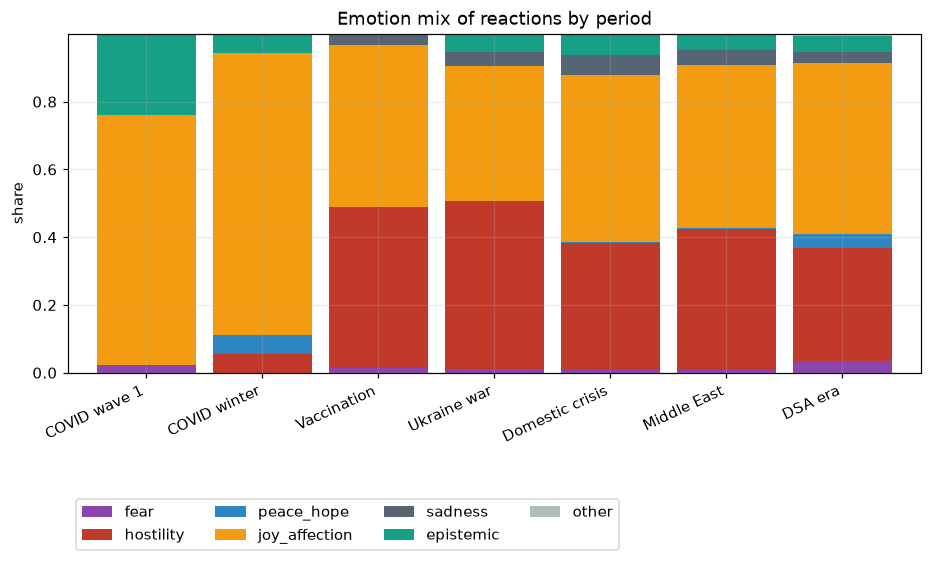

phase,sadness,joy_affection,other,hostility,epistemic,peace_hope,fear
enum,f64,f64,f64,f64,f64,f64,f64
"""COVID wave 1""",0.0,0.738095,0.0,0.0,0.238095,0.0,0.02381
"""COVID winter""",0.0,0.833333,0.0,0.055556,0.055556,0.055556,0.0
"""Vaccination""",0.029075,0.477005,0.000005,0.476902,0.004281,0.000014,0.012718
"""Ukraine war""",0.043975,0.396944,0.000084,0.494471,0.052135,0.001011,0.011379
"""Domestic crisis""",0.058057,0.4935,0.00031,0.375377,0.062389,0.003697,0.00667
"""Middle East""",0.046014,0.479643,0.000157,0.416148,0.046291,0.004673,0.007074
"""DSA era""",0.030117,0.507402,0.005298,0.333867,0.049229,0.039661,0.034426


In [55]:
byp = emotion_profile(SCp, by=("phase",))
order = [p for p in PHASES["phase"].to_list() if p in set(byp["phase"])]
pp = byp.to_pandas().set_index("phase").loc[order][fams(byp)]
ax = pp.plot(kind="bar", stacked=True, figsize=(10, 4), color=[FAM_COL[c] for c in pp.columns], width=0.85)
ax.set_ylabel("share"); ax.set_xlabel(""); ax.set_title("Emotion mix of reactions by period"); plt.xticks(rotation=25, ha="right")
ax.legend(ncol=4, bbox_to_anchor=(0, -0.35), loc="upper left"); savefig("02_emotion_by_period"); plt.show()
byp.write_csv(FIG / "02_emotion_profile_by_period.csv"); byp.sort("phase")

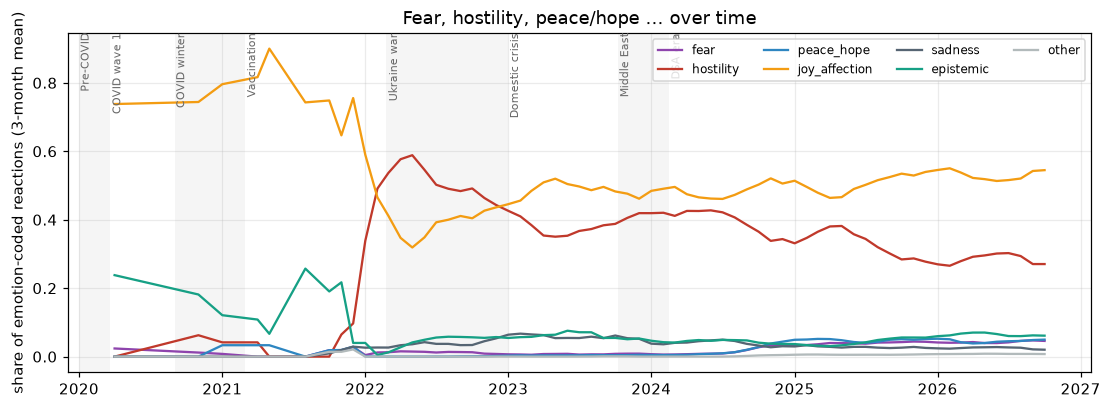

In [56]:
bym = emotion_profile(SC.with_columns(pl.col("day").dt.truncate("1mo").alias("month")), by=("month",)).sort("month")
fig, ax = plt.subplots(figsize=(12, 4))
for f in fams(bym):
    ax.plot(bym["month"].to_pandas(), bym[f].to_pandas().rolling(3, min_periods=1).mean(), label=f, color=FAM_COL[f])
ax.set_ylabel("share of emotion-coded reactions (3-month mean)"); shade_phases(ax, PHASES); ax.legend(ncol=4, fontsize=8)
ax.set_title("Fear, hostility, peace/hope ... over time"); savefig("02_emotion_over_time"); plt.show()

**Top posts per emotion family** - ranked by the Wilson lower bound of that family's share among all reactions (min. reactions as above).

In [57]:
def top_family(fam, n=5):
    col = f"fam_{fam}"
    if col not in SC.columns: return None
    return (SC.with_columns(wilson_lower(pl.col(col), pl.col("n_reactions")).alias(f"{fam}_wilson"))
              .sort(f"{fam}_wilson", descending=True).head(n)
              .select("channel", "day", pl.col(col).alias(f"{fam}_reactions"), "n_reactions", f"{fam}_wilson", "snippet", "link"))
for f in ("fear", "hostility", "peace_hope", "sadness"):
    print("=====", f); r = top_family(f)
    if r is not None: display(r); r.write_csv(FIG / f"02_top_{f}.csv")

===== fear


channel,day,fear_reactions,n_reactions,fear_wilson,snippet,link
str,date,i64,i64,f64,str,str
"""satellit_de""",2022-06-22,60,62,0.889793,"""Brand auf Ölraffinerie in Nowoschachtinsk: Das Werk gilt als die größt…","""https://t.me/satellit_de/9666"""
"""CompactMagazin""",2022-06-01,26,26,0.871267,"""💥Akutes Koronarsyndrom: Bevor der Herzinfarkt kommt Das akute Koronars…","""https://t.me/CompactMagazin/18498"""
"""satellit_de""",2022-04-04,46,48,0.860241,"""🇷🇺 Stärke 4,3: Erneut Erdbeben auf Sachalin Die russische Fernost-Inse…","""https://t.me/satellit_de/2100"""
"""satellit_de""",2022-06-14,53,56,0.853925,"""Das Gebäude der Kunstresidenz des Sozvezdiye-Yoldyzlyk-Festivals brenn…","""https://t.me/satellit_de/8969"""
"""CompactMagazin""",2022-09-19,50,53,0.846296,"""💥Panik und Stress: Wie Angst unser Leben verkürzt. Unter Panikattacken…","""https://t.me/CompactMagazin/21188"""


===== hostility


channel,day,hostility_reactions,n_reactions,hostility_wilson,snippet,link
str,date,i64,i64,f64,str,str
"""CompactMagazin""",2025-01-24,1028,1033,0.988719,"""🌹🕯️ Aschaffenburg: Der Blockadering der Antifa rund um die Gedächtniss…","""https://t.me/CompactMagazin/35519"""
"""CompactMagazin""",2024-12-12,453,454,0.98763,"""Scholzens billiger Trick 🍞🍎🍗 Zitat des Tages: „Vielleicht war der Kanz…","""https://t.me/CompactMagazin/34745"""
"""CompactMagazin""",2023-03-29,303,303,0.98748,"""Zitat des Tages: „Ja, mit den Grünen kann man Armut überwinden“ (Ricar…","""https://t.me/CompactMagazin/24622"""
"""CompactMagazin""",2025-01-24,1069,1076,0.986632,"""🌹🕯️ Aschaffenburg: Makaber – Linke Propaganda am Tatort im Schöntalpar…","""https://t.me/CompactMagazin/35520"""
"""CompactMagazin""",2022-06-23,277,277,0.986321,"""💥 Skandal: Lauterbach (SPD) beleidigt impffreie Pflegekräfte Mit einer…","""https://t.me/CompactMagazin/19067"""


===== peace_hope


channel,day,peace_hope_reactions,n_reactions,peace_hope_wilson,snippet,link
str,date,i64,i64,f64,str,str
"""DruschbaFM""",2024-03-22,119,119,0.968727,"""⚡️Über 50 medizinische Notfallteams fahren nach Krasnogorsk bei Moskau…","""https://t.me/DruschbaFM/35352"""
"""oliverjanich""",2024-05-31,214,225,0.914591,"""Beten Leute, das spielt sich alles JETZT ab.""","""https://t.me/oliverjanich/138587"""
"""apolut""",2026-04-04,33,33,0.895727,"""Wo sich Verstand und Mitgefühl paaren | Von Dirk C. Fleck Ein Meinungs…","""https://t.me/apolut/11830"""
"""oliverjanich""",2024-05-31,253,275,0.881849,"""Die Polizei hat wirklich schnell reagiert und sofort auf den Angreifer…","""https://t.me/oliverjanich/138589"""
"""oliverjanich""",2024-05-31,223,243,0.876299,"""Es gibt Gerüchte, der Polizist sei verstorben Ich habe – unter Vorbeha…","""https://t.me/oliverjanich/138617"""


===== sadness


channel,day,sadness_reactions,n_reactions,sadness_wilson,snippet,link
str,date,i64,i64,f64,str,str
"""satellit_de""",2022-12-29,95,95,0.961134,"""⚡️Brasilianische Fußball-Legende Pelé im Alter von 82 Jahren gestorben…","""https://t.me/satellit_de/20505"""
"""satellit_de""",2022-11-21,73,73,0.950006,"""Bei einem Erdbeben der Stärke 5,6 sind am Montag in der indonesischen …","""https://t.me/satellit_de/18899"""
"""DruschbaFM""",2022-10-31,72,72,0.949347,"""Zahl der Todesopfer nach Einsturz einer Schrägseilbrücke im Westen Ind…","""https://t.me/DruschbaFM/7677"""
"""epochtimesde""",2024-04-08,68,68,0.946527,"""Neunjähriger wird in Baden-Württemberg von Pferd mitgeschleift und sti…","""https://t.me/epochtimesde/54375"""
"""DruschbaFM""",2023-02-09,151,154,0.944296,"""❗️ Die Zahl der Todesopfer durch das Erdbeben in der Türkei ist auf 12…","""https://t.me/DruschbaFM/12730"""


**Author side:** emotion families of the emoji the channels themselves write in their texts - compared with the audience's reactions.

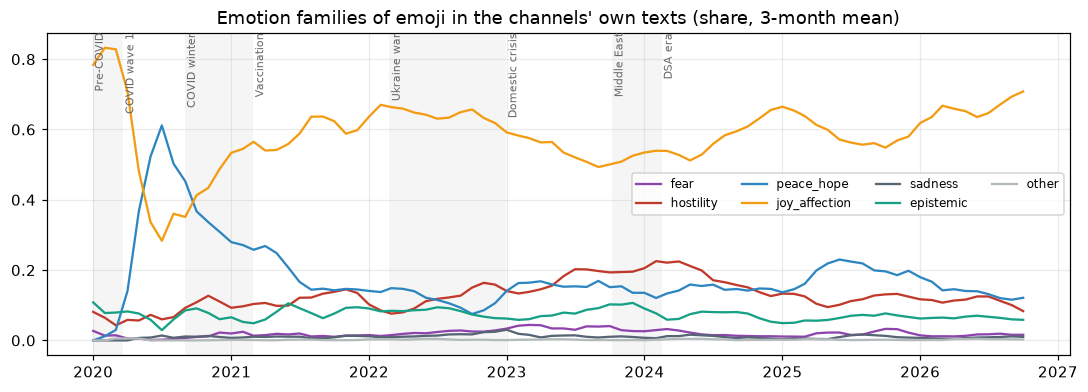

In [58]:
te = text_emotions(df.filter(pl.col("has_text")), CB)
te_m = (te.filter(~pl.col("family").is_in(["none", "unclassified"]))
          .with_columns(pl.col("day").dt.truncate("1mo").alias("month")).group_by("month", "family").len()
          .pivot(on="family", index="month", values="len").fill_null(0).sort("month"))
cols = [f for f in FAM_ORDER if f in te_m.columns]
tot = te_m.select(pl.sum_horizontal(cols).alias("t"))["t"]
fig, ax = plt.subplots(figsize=(12, 3.8))
for f in cols:
    ax.plot(te_m["month"].to_pandas(), (te_m[f] / tot).to_pandas().rolling(3, min_periods=1).mean(), label=f, color=FAM_COL[f])
shade_phases(ax, PHASES); ax.legend(ncol=4, fontsize=8); ax.set_title("Emotion families of emoji in the channels' own texts (share, 3-month mean)")
savefig("02_text_emotion_over_time"); plt.show()

## Notes
* Reaction counts of old posts can only reflect reactions that still exist at download time.
* Premium "custom emoji" reactions appear as `reaction_custom_<id>` (ids, not pictures).
* Reactions are not comparable across channels that have them switched off or limited.

## References

**References for the emotion coding and the rankings** (written from memory - verify before citing):

* Ekman, P. (1992). An argument for basic emotions. *Cognition & Emotion* 6(3-4), 169-200.
* Kralj Novak, P., Smailovic, J., Sluban, B. & Mozetic, I. (2015). Sentiment of emojis. *PLoS ONE* 10(12), e0144296 (Emoji Sentiment Ranking, CLARIN.SI).
* Matsumoto, D. & Ekman, P. (2004). The relationship among expressions, labels, and descriptions of contempt. *J. Personality and Social Psychology* 87(4), 529-540.
* Plutchik, R. (2001). The nature of emotions. *American Scientist* 89(4), 344-350.
* Pool, C. & Nissim, M. (2016). Distant supervision for emotion detection using Facebook reactions. *Proc. PEOPLES workshop, COLING 2016*.
* Russell, J. A. (1980). A circumplex model of affect. *J. Personality and Social Psychology* 39(6), 1161-1178.
* Silvia, P. J. (2010). Confusion and interest: the role of knowledge emotions in aesthetic experience. *Psychology of Aesthetics, Creativity, and the Arts* 4(2), 75-80.
* Sternberg, R. J. (2003). A duplex theory of hate: development and application to terrorism, massacres, and genocide. *Review of General Psychology* 7(3), 299-328.
* Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *JASA* 22(158), 209-212; Miller, E. (2009), *How not to sort by average rating* (web essay).